In [1]:
from google.colab import files

# This will prompt you to select files from your local machine to upload
uploaded = files.upload()

for fn in uploaded.keys():
  print(f'User uploaded file "{fn}" with length {len(uploaded[fn])} bytes')

Saving Electric_Vehicle_(EV)_Charging_Data_-_Municipal_Lots_and_Garages_20261104.csv to Electric_Vehicle_(EV)_Charging_Data_-_Municipal_Lots_and_Garages_20261104.csv
User uploaded file "Electric_Vehicle_(EV)_Charging_Data_-_Municipal_Lots_and_Garages_20261104.csv" with length 55208433 bytes


In [2]:
!pip install pandas numpy matplotlib seaborn statsmodels scikit-learn

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from google.colab import files
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Saving Electric_Vehicle_(EV)_Charging_Data_-_Municipal_Lots_and_Garages_20261104.csv to Electric_Vehicle_(EV)_Charging_Data_-_Municipal_Lots_and_Garages_20261104 (1).csv
Dataset loaded successfully!
Shape: (258755, 15)


,Date,Station Name,Location Name,Country,Charge Box ID,Connector ID,Driver ID,ID Tag,Connected Time,Disconnected Time,Charge Duration (min),Connected Duration (min),Energy Provided (kWh),Session Status,Invalidity Reason
0,08/21/2025,101013,JGU - Jerome Gun Hill Road Municipal Parking G...,USA,101013,1,4a37c773-2997-472d-a5e1-0dfc26bf4883,ADJRKBZ9BBMW0B0LMVCA,19:10:54.0000000,07:11:12.0000000,720.3,720.3,41.369,PAID,NaN
1,08/21/2025,101014,JGU - Jerome Gun Hill Road Municipal Parking G...,USA,101014,1,7fa6b416-4196-4120-b6bd-409e1ad65ba6,78I78199YN3TRVI1OSMH,16:53:00.0000000,20:29:07.0000000,160.1,216.116666667,15.814,PAID,NaN
2,08/21/2025,101016,JGU - Jerome Gun Hill Road Municipal Parking G...,USA,101016,1,97b09152-a9c2-4113-a7ab-aef174f958ca,V7IA0NBZQ3POKCQIYSRR,23:08:38.0000000,09:33:03.0000000,570.666666667,624.416666667,31.867,PAID,NaN
3,08/21/2025,101016,JGU - Jerome Gun Hill Road Municipal Parking G...,USA,101016,1,43d4f216-5ed2-42b6-bafe-116d2b71f214,V9CBB51Z13C27U3KBW0C,18:36:40.0000000,22:47:25.0000000,250.416666667,250.75,24.139,PAID,NaN
4,08/21/2025,101016,JGU - Jerome Gun Hill Road Municipal Parking G...,USA,101016,1,00b32c8f-fe48-46ee-a69d-8303d03db5c1,ZTDXRM7IEYNLIO2OU259,09:37:32.0000000,17:50:59.0000000,493.45,493.45,52.729,PAID,NaN


Cell 3 — Understand the dataset

In [4]:
print("Dataset information:")
print(df.info())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nSession status:")
print(df["Session Status"].value_counts(dropna=False))

print("\nStatistical summary:")
display(df.describe(include="all").T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 258755 entries, 0 to 258754
Data columns (total 15 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Date                      258755 non-null  object 
 1   Station Name              258755 non-null  object 
 2   Location Name             258726 non-null  object 
 3   Country                   178296 non-null  object 
 4   Charge Box ID             258755 non-null  object 
 5   Connector ID              258755 non-null  int64  
 6   Driver ID                 247120 non-null  object 
 7   ID Tag                    258755 non-null  object 
 8   Connected Time            258755 non-null  object 
 9   Disconnected Time         258755 non-null  object 
 10  Charge Duration (min)     258755 non-null  object 
 11  Connected Duration (min)  258755 non-null  object 
 12  Energy Provided (kWh)     258755 non-null  float64
 13  Session Status         

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,258755,1857,06/22/2024,379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Station Name,258755,166,101337,19071,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location Name,258726,25,QBO - Queens Borough Hall Municipal Parking Ga...,57539,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,178296,1,USA,178296,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Charge Box ID,258755,183,veefil-602200189,19071,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Connector ID,258755.0,NaN,NaN,NaN,1.41998,0.493556,1.0,1.0,1.0,2.0,2.0
Driver ID,247120,19148,e82bc7ab-b885-4e85-bf10-7e46ffce43bb,1912,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ID Tag,258755,31728,ORVE1RG0GAUIJ0MT7WGU,1905,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Connected Time,258755,81067,20:10:36,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Disconnected Time,258755,81281,19:08:15,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Cell 4 — Data cleaning and preprocessing


In [5]:
df.columns = df.columns.str.strip()

df["Date"] = pd.to_datetime(
    df["Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

df["Energy Provided (kWh)"] = pd.to_numeric(
    df["Energy Provided (kWh)"],
    errors="coerce"
)

# Remove invalid dates and missing energy values
df = df.dropna(subset=["Date", "Energy Provided (kWh)"])

# Keep only non-negative energy values
df = df[df["Energy Provided (kWh)"] >= 0]

# Select valid charging session statuses
VALID_STATUSES = ["PAID", "ROAMING"]

df["Session Status"] = (
    df["Session Status"].astype(str).str.strip().str.upper()
)

df = df[df["Session Status"].isin(VALID_STATUSES)].copy()

print("Cleaned dataset shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Total energy:", df["Energy Provided (kWh)"].sum(), "kWh")

Cleaned dataset shape: (252973, 15)
Date range: 2021-07-31 00:00:00 to 2026-09-08 00:00:00
Total energy: 5784085.284 kWh


Cell 5 — Create daily E
V charging demand

In [6]:
daily = (
    df.groupby("Date")["Energy Provided (kWh)"]
      .sum()
      .sort_index()
)

# Create a continuous daily time series
daily = daily.asfreq("D")

# Assumption: dates with no recorded sessions represent zero demand
daily = daily.fillna(0)

daily.name = "Daily_Demand"

print("Daily observations:", len(daily))
display(daily.head(10))

Daily observations: 1866


,Daily_Demand
Date,
2021-07-31,258.588
2021-08-01,347.993
2021-08-02,347.523
2021-08-03,379.353
2021-08-04,494.058
2021-08-05,408.988
2021-08-06,288.444
2021-08-07,286.727
2021-08-08,362.030


Cell 6 — Plot daily demand

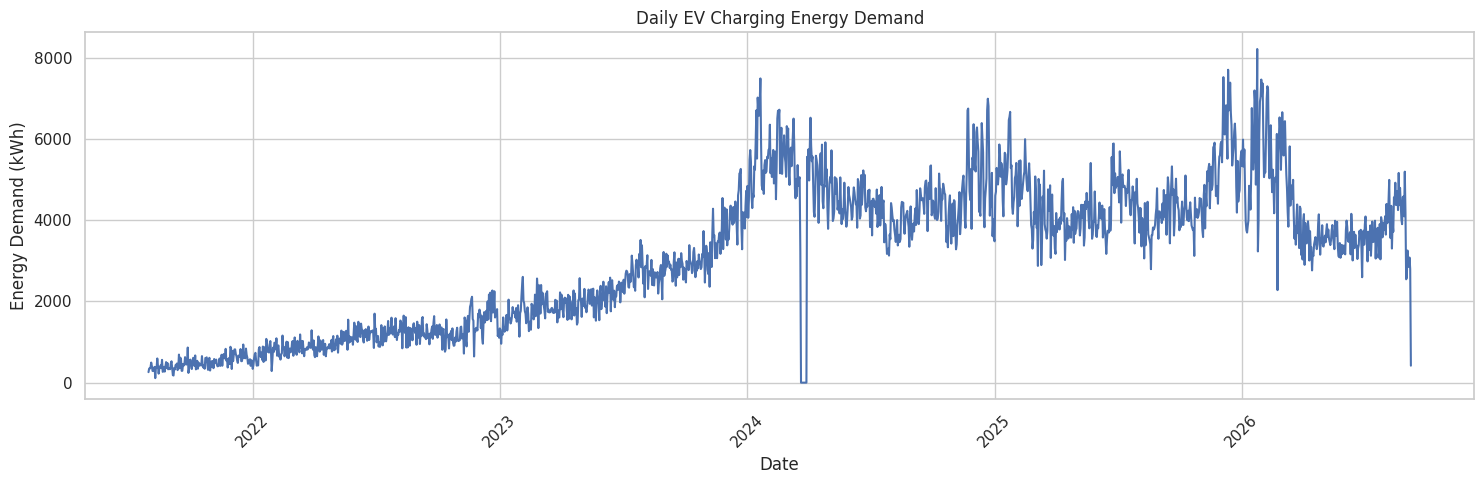

In [7]:
plt.figure(figsize=(15, 5))

plt.plot(daily.index, daily.values)

plt.title("Daily EV Charging Energy Demand")
plt.xlabel("Date")
plt.ylabel("Energy Demand (kWh)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Cell 7 — Trend analysis

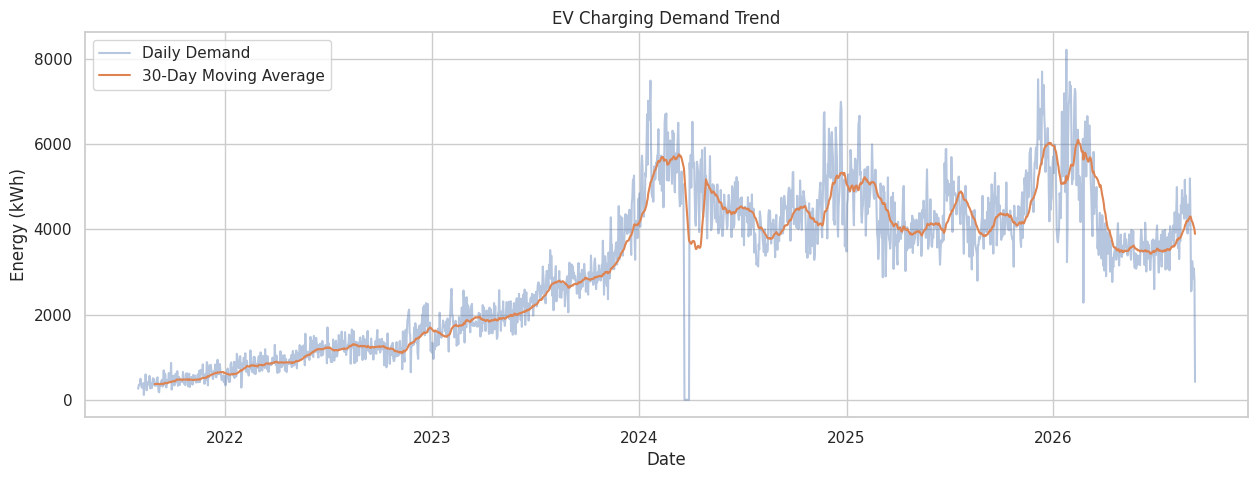

In [8]:
rolling_mean = daily.rolling(30).mean()
rolling_std = daily.rolling(30).std()

plt.figure(figsize=(15, 5))

plt.plot(daily, alpha=0.4, label="Daily Demand")
plt.plot(rolling_mean, label="30-Day Moving Average")

plt.title("EV Charging Demand Trend")
plt.xlabel("Date")
plt.ylabel("Energy (kWh)")
plt.legend()
plt.show()

Cell 8 — Monthly and weekly trends

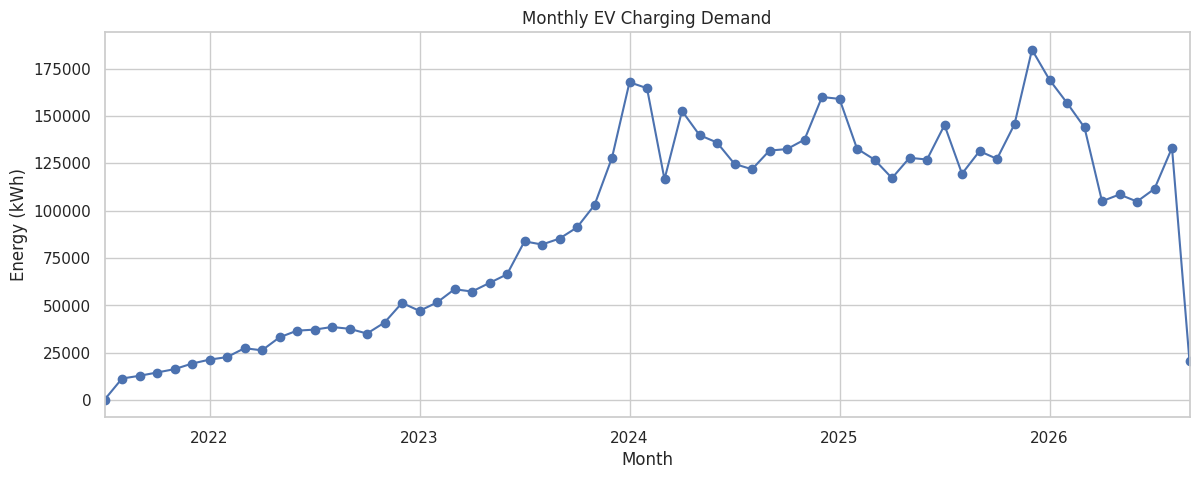

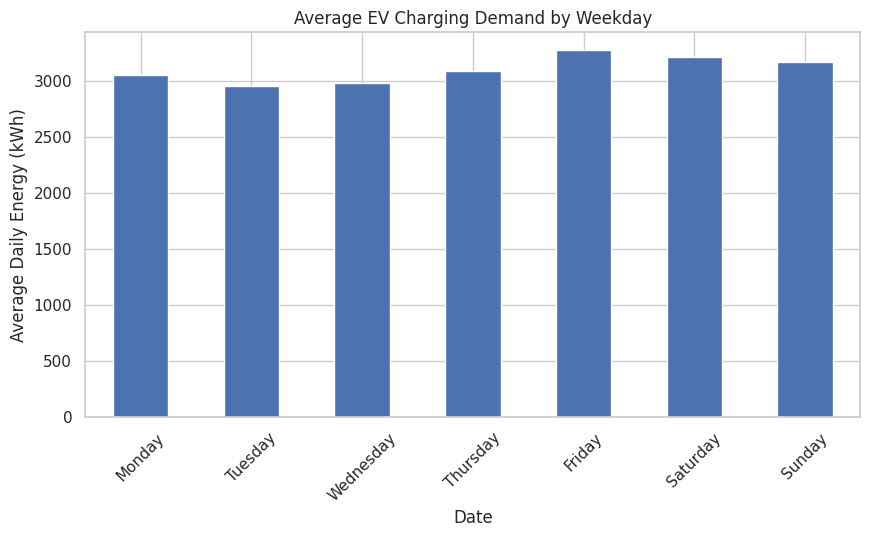

In [9]:
monthly = daily.resample("ME").sum()

plt.figure(figsize=(14, 5))
monthly.plot(kind="line", marker="o")

plt.title("Monthly EV Charging Demand")
plt.xlabel("Month")
plt.ylabel("Energy (kWh)")
plt.show()

weekday_demand = daily.groupby(daily.index.day_name()).mean()

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_demand = weekday_demand.reindex(weekday_order)

plt.figure(figsize=(10, 5))
weekday_demand.plot(kind="bar")

plt.title("Average EV Charging Demand by Weekday")
plt.ylabel("Average Daily Energy (kWh)")
plt.xticks(rotation=45)
plt.show()

Cell 9 — Station-wise analysis

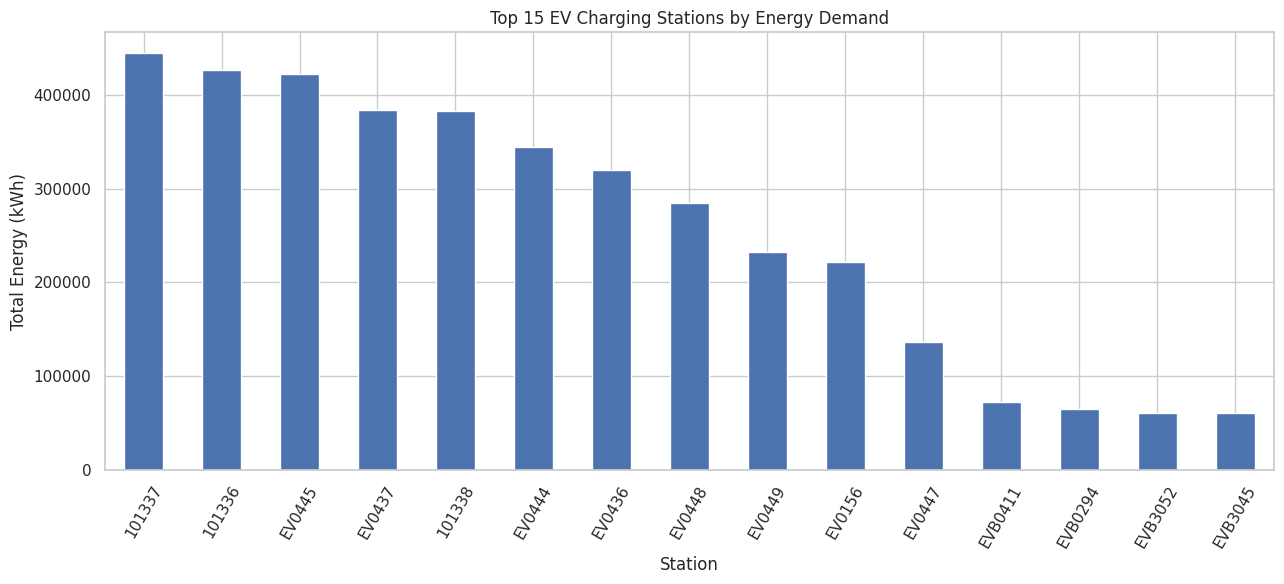

,Energy Provided (kWh)
Station Name,
101337,444668.261
101336,427198.117
EV0445,422770.524
EV0437,383985.821
101338,382641.146
EV0444,344583.623
EV0436,319684.569
EV0448,285215.075
EV0449,232288.831


In [10]:
station_demand = (
    df.groupby("Station Name")["Energy Provided (kWh)"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(13, 6))

station_demand.head(15).plot(kind="bar")

plt.title("Top 15 EV Charging Stations by Energy Demand")
plt.xlabel("Station")
plt.ylabel("Total Energy (kWh)")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

display(station_demand.head(15))

Cell 10 — Check stationarity using ADF test

In [11]:
adf_result = adfuller(daily.dropna())

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])

if adf_result[1] < 0.05:
    print("The time series is stationary.")
else:
    print("The time series is non-stationary.")

ADF Statistic: -2.1331336604138755
p-value: 0.2314017385626554
The time series is non-stationary.


Cell 11 — Differencing

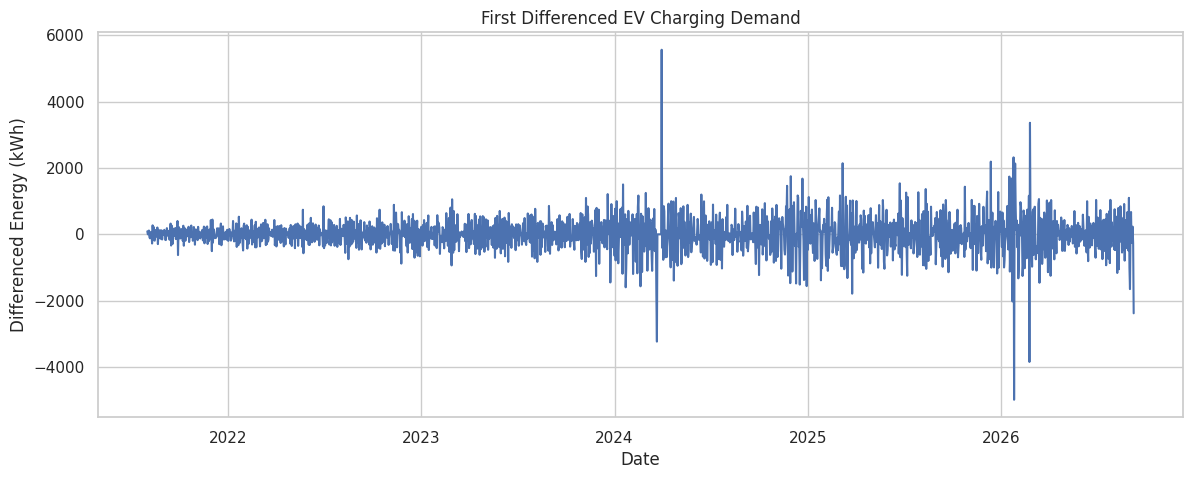

Differenced ADF p-value: 7.075843365637611e-22


In [12]:
daily_diff = daily.diff().dropna()

plt.figure(figsize=(14, 5))

plt.plot(daily_diff)

plt.title("First Differenced EV Charging Demand")
plt.xlabel("Date")
plt.ylabel("Differenced Energy (kWh)")
plt.show()

adf_diff = adfuller(daily_diff)

print("Differenced ADF p-value:", adf_diff[1])

Cell 12 — Train, validation and test split
We use chronological splitting to avoid future information leaking into the past.
- 70% training
- 10% validation
- 20% testing

In [13]:
n = len(daily)

train_end = int(n * 0.70)
val_end = int(n * 0.80)

train = daily.iloc[:train_end]
validation = daily.iloc[train_end:val_end]
test = daily.iloc[val_end:]

train_validation = daily.iloc[:val_end]

print("Training records:", len(train))
print("Validation records:", len(validation))
print("Testing records:", len(test))

Training records: 1306
Validation records: 186
Testing records: 374


Cell 13 — Define forecasting models
We compare **two simple baselines**, then AR, MA, ARMA, ARIMA, SARIMA, Exponential Smoothing and a **Random Forest** machine-learning model.

The baselines are the "benchmark to beat": if a fancy model cannot do better than *"same day last week"*, it is not adding value.

In [ ]:
candidates = {
    # ---- Baselines (the benchmark every other model must beat) ----
    "Baseline: Naive (last value)": ("naive", None),
    "Baseline: Same day last week": ("snaive", None),

    # ---- Classical statistical models ----
    "AR(1)": ("arima", (1, 0, 0)),
    "MA(1)": ("arima", (0, 0, 1)),
    "ARMA(1,1)": ("arima", (1, 0, 1)),
    "ARIMA(1,1,1)": ("arima", (1, 1, 1)),
    "ARIMA(2,1,1)": ("arima", (2, 1, 1)),
    "ARIMA(1,1,2)": ("arima", (1, 1, 2)),
    "SARIMA(1,0,1)(1,0,1,7)": (
        "sarima", ((1, 0, 1), (1, 0, 1, 7))
    ),
    "SARIMA(1,1,1)(1,1,1,7)": (
        "sarima", ((1, 1, 1), (1, 1, 1, 7))
    ),
    "Exponential Smoothing": ("ets", None),

    # ---- Machine learning model ----
    "Random Forest (lag features)": ("rf", None),
}

Cell 13b — Baseline and Random Forest helper models

**Baselines (very simple rules):**
- *Naive*: "tomorrow will be the same as today".
- *Same day last week*: "this Monday will look like last Monday".

**Random Forest with lag features:** a Random Forest is a team of many decision trees that vote. We give it clues about the past (a "lag" is just a past value):
- demand 1, 2, 3, 7 and 14 days ago
- the average of the last 7 and last 30 days
- the day of the week, month and day of the month

To forecast many days ahead it predicts one day, adds that prediction to the history, then predicts the next day (like writing a story one sentence at a time using your own previous sentences).

In [ ]:
from sklearn.ensemble import RandomForestRegressor


def make_future_index(series, steps):
    """Dates that come right after the last date of the series."""
    return pd.date_range(
        start=series.index[-1] + pd.Timedelta(days=1),
        periods=steps,
        freq="D"
    )


class NaiveBaseline:
    """Tomorrow = today. Repeats the last known value."""

    def __init__(self, series):
        self.series = series
        self.last_value = series.iloc[-1]

    def forecast(self, steps):
        idx = make_future_index(self.series, steps)
        return pd.Series(self.last_value, index=idx)


class SeasonalNaiveBaseline:
    """Same weekday as last week. Repeats the last 7 days again and again."""

    def __init__(self, series, season=7):
        self.series = series
        self.last_season = series.iloc[-season:].values

    def forecast(self, steps):
        idx = make_future_index(self.series, steps)
        values = np.resize(self.last_season, steps)  # repeats the pattern
        return pd.Series(values, index=idx)


class LagRandomForest:
    """Random Forest that learns from past demand (lag features)."""

    LAGS = [1, 2, 3, 7, 14]
    WINDOW = 30  # we need 30 days of history before the first prediction
    FEATURE_NAMES = (
        [f"lag_{l}" for l in LAGS]
        + ["mean_last_7", "mean_last_30", "day_of_week", "month", "day_of_month"]
    )

    def __init__(self, n_estimators=200, random_state=42):
        self.model = RandomForestRegressor(
            n_estimators=n_estimators,
            min_samples_leaf=2,
            random_state=random_state,
            n_jobs=-1
        )

    def _features(self, history, date):
        lags = [history[-lag] for lag in self.LAGS]
        return lags + [
            np.mean(history[-7:]),
            np.mean(history[-30:]),
            date.dayofweek,
            date.month,
            date.day
        ]

    def fit(self, series):
        self.series = series
        values = series.values.astype(float)

        X, y = [], []
        for i in range(self.WINDOW, len(values)):
            X.append(self._features(values[:i], series.index[i]))
            y.append(values[i])

        self.model.fit(np.array(X), np.array(y))
        return self

    def forecast(self, steps):
        idx = make_future_index(self.series, steps)
        history = list(self.series.values.astype(float))

        self.model.set_params(n_jobs=1)  # faster for one-row predictions

        predictions = []
        for date in idx:
            x = np.array(self._features(history, date)).reshape(1, -1)
            p = max(self.model.predict(x)[0], 0)
            predictions.append(p)
            history.append(p)  # feed our own prediction back in

        return pd.Series(predictions, index=idx)

Cell 14 — Model fitting function

In [ ]:
def fit_model(series, model_info):

    model_type, params = model_info

    if model_type == "naive":
        model = NaiveBaseline(series)

    elif model_type == "snaive":
        model = SeasonalNaiveBaseline(series, season=7)

    elif model_type == "rf":
        model = LagRandomForest().fit(series)

    elif model_type == "arima":
        model = ARIMA(
            series,
            order=params
        ).fit()

    elif model_type == "sarima":
        order, seasonal_order = params

        model = ARIMA(
            series,
            order=order,
            seasonal_order=seasonal_order
        ).fit()

    elif model_type == "ets":
        model = ExponentialSmoothing(
            series,
            trend="add",
            damped_trend=True,
            seasonal="add",
            seasonal_periods=7
        ).fit()

    return model

Cell 15 — Select the best model using validation data

In [ ]:
validation_results = []

for name, info in candidates.items():

    try:
        model = fit_model(train, info)

        predictions = model.forecast(len(validation))
        predictions = np.maximum(predictions, 0)

        rmse = np.sqrt(
            mean_squared_error(validation, predictions)
        )

        mae = mean_absolute_error(validation, predictions)

        validation_results.append({
            "Model": name,
            "Validation MAE": mae,
            "Validation RMSE": rmse
        })

        print(name, "completed")

    except Exception as e:
        print(name, "failed:", str(e)[:150])

validation_table = pd.DataFrame(validation_results)

validation_table = validation_table.sort_values(
    "Validation RMSE"
)

display(validation_table)

best_model_name = validation_table.iloc[0]["Model"]

print("Best model based on validation RMSE:", best_model_name)

Cell 16 — Compare all models on the test dataset

In [ ]:
test_results = []
test_predictions = {}

for name, info in candidates.items():

    try:
        model = fit_model(train_validation, info)

        predictions = model.forecast(len(test))
        predictions = np.maximum(predictions, 0)

        test_predictions[name] = predictions

        mae = mean_absolute_error(test, predictions)

        mse = mean_squared_error(test, predictions)

        rmse = np.sqrt(mse)

        # MAPE divides by the actual value, so days with zero demand
        # would blow it up. We calculate it only on days with demand > 0.
        nonzero = test.values != 0
        mape = np.mean(
            np.abs(
                (test.values[nonzero] - predictions.values[nonzero])
                / test.values[nonzero]
            )
        ) * 100

        r2 = r2_score(test, predictions)

        test_results.append({
            "Model": name,
            "MAE": mae,
            "MSE": mse,
            "RMSE": rmse,
            "MAPE (%) non-zero days": mape,
            "R2": r2
        })

        print(name, "completed")

    except Exception as e:
        print(name, "failed:", str(e)[:150])

results = pd.DataFrame(test_results)

results = results.sort_values("RMSE")

display(results)

Cell 16b — Did our models beat the baseline?

The baseline is the "class average". A model is only worth using if it scores **better** than "same day last week". A positive percentage means the model made smaller mistakes than the baseline.

In [ ]:
baseline_name = "Baseline: Same day last week"

baseline_rmse = results.loc[results["Model"] == baseline_name, "RMSE"].iloc[0]

baseline_check = results[["Model", "MAE", "RMSE"]].copy()

baseline_check["RMSE improvement vs baseline (%)"] = (
    (baseline_rmse - baseline_check["RMSE"]) / baseline_rmse * 100
)

baseline_check["Beats baseline?"] = baseline_check["RMSE"] < baseline_rmse

display(baseline_check)

n_beat = int(baseline_check["Beats baseline?"].sum())
print(f"{n_beat} model(s) beat the 'same day last week' baseline.")

Cell 17 — Model accuracy comparison graph

In [ ]:
plt.figure(figsize=(14, 5))

# grey = baseline, green = model chosen on validation data, blue = other models
colors = []
for m in results["Model"]:
    if m.startswith("Baseline"):
        colors.append("gray")
    elif m == best_model_name:
        colors.append("green")
    else:
        colors.append("steelblue")

plt.bar(results["Model"], results["RMSE"], color=colors)

plt.title("Model Comparison Using RMSE (grey = baseline, green = chosen model)")
plt.ylabel("RMSE (kWh)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

Cell 17b — What did the Random Forest learn?

This shows which clues (features) the Random Forest relied on most. A tall bar means that clue was very useful for predicting demand.

In [ ]:
rf_model = fit_model(train_validation, candidates["Random Forest (lag features)"])

importance = pd.Series(
    rf_model.model.feature_importances_,
    index=LagRandomForest.FEATURE_NAMES
).sort_values()

plt.figure(figsize=(9, 5))
importance.plot(kind="barh")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

Cell 18 — Actual vs predicted graph

To stay consistent, we plot the **same model that is used for the final forecast**: the one chosen on validation data. We never pick the model by looking at the test set, because that would be like choosing your exam answers after seeing the marks.

In [ ]:
# Same model that Cell 19 will use for the final forecast
chosen_predictions = test_predictions[best_model_name]
baseline_predictions = test_predictions["Baseline: Same day last week"]

plt.figure(figsize=(15, 6))

plt.plot(test.index, test.values, label="Actual")
plt.plot(
    test.index,
    chosen_predictions.values,
    label=f"Predicted ({best_model_name})"
)
plt.plot(
    test.index,
    baseline_predictions.values,
    linestyle="--",
    alpha=0.6,
    label="Baseline (same day last week)"
)

plt.title("Actual vs Predicted EV Charging Demand")
plt.xlabel("Date")
plt.ylabel("Energy (kWh)")
plt.legend()
plt.show()

print("Model chosen on validation data (used for final forecast):", best_model_name)
print("Best model on the test set (for reference only):", results.iloc[0]["Model"])

Cell 19 — Forecast the next 30 days
We use the best model selected on validation data, then refit it on the complete historical dataset.

In [ ]:
best_info = candidates[best_model_name]

final_model = fit_model(daily, best_info)

forecast_steps = 30

future_forecast = final_model.forecast(forecast_steps)

future_forecast = np.maximum(future_forecast, 0)

future_dates = pd.date_range(
    start=daily.index[-1] + pd.Timedelta(days=1),
    periods=forecast_steps,
    freq="D"
)

forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Forecasted Energy (kWh)": future_forecast.values
})

display(forecast_df)

Cell 20 — Future demand graph

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily.index[-90:],
    daily.values[-90:],
    label="Historical Demand"
)

plt.plot(
    future_dates,
    future_forecast.values,
    marker="o",
    label="Next 30 Days Forecast"
)

plt.title("30-Day EV Charging Demand Forecast")
plt.xlabel("Date")
plt.ylabel("Energy (kWh)")
plt.legend()
plt.tight_layout()
plt.show()

Cell 21 — Export results

In [ ]:
forecast_df.to_csv(
    "EV_Charging_30_Day_Forecast.csv",
    index=False
)

results.to_csv(
    "EV_Model_Comparison.csv",
    index=False
)

files.download("EV_Charging_30_Day_Forecast.csv")
files.download("EV_Model_Comparison.csv")